# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** Bireysel Proje (Yusuf Yurtman) • **Proje:** Popüler Mobil Uygulamaların İzin Talepleri ve Veri Gizliliği Kapsamında Karşılaştırılması • **Ekip görevleri:** Yusuf Yurtman (Veri toplama, veri temizleme, istatistiksel analiz, görselleştirme ve raporlama)

Bu notebook projenin Google Play Store uygulama izin verilerine uyarlanmış çalışır halidir.

## A. Veri tanıtımı
- **Veri setinin adı ve bağlantısı:** `mobil_uygulama_izinleri.csv` — [GitHub Depo Bağlantısı](https://github.com/yurtman421/mobil-uygulama-gizlilik-analizi)
- **Veri kaynağı / lisans / erişim tarihi:** Google Play Store resmi uygulama mağaza sayfaları ("Veri Güvenliği" ve "Uygulama İzinleri" bölümleri) / Kamuya açık mağaza verisi (Açık Lisans - Eğitim amaçlı derleme) / Erişim Tarihi: Kasım 2026.
- **CSV mi, JSON mu?:** CSV formatında (`mobil_uygulama_izinleri.csv`).
- **Satır ve sütunların anlamı:** Her bir satır incelenen popüler bir mobil uygulamayı temsil eder. Sütunlar: `uygulama_adi` (Uygulama ismi), `kategori` (Sosyal Medya veya Mobil Oyun), `toplam_izin_sayisi` (Uygulamanın talep ettiği toplam izin adedi), `hassas_izin_sayisi` (Veri gizliliği açısından kritik izinlerin toplam adedi) ve `konum`, `mikrofon`, `kamera`, `rehber` izinlerinin varlığı (1: Talep ediyor, 0: Talep etmiyor).
- **Ölçü birimi ve gözlem sayısı:** Ölçü birimi **Adet** (izin sayısı) ve **İkili/Binary (1/0)** göstergedir. Gözlem sayısı toplam **20 mobil uygulama** (10 Sosyal Medya ve 10 Mobil Oyun) olup veri seti boyutu `(20, 8)`'dir.
- **Gerçek mi / açık kaynak mı / temsili mi?:** Google Play Store üzerinde en çok indirilen popüler uygulamaların kamuya açık mağaza sayfalarından derlenmiş **gerçek ve açık kaynaklı** gözlem verisidir.
- **Ekip üyelerinin görevleri:** Yusuf Yurtman — 20 popüler uygulamanın mağaza izin verilerinin toplanması, CSV formatında yapılandırılması, Python (`pandas` ve `matplotlib`) ile betimsel istatistiklerinin hesaplanması ve grafiksel raporlanması.

## B. Başlangıç: Proje veri setinin oluşturulması ve okunması
Aşağıdaki kod bloğu araştırma kapsamında derlenen 20 mobil uygulamanın izin verisini `mobil_uygulama_izinleri.csv` dosyasına kaydeder ve `veri_yolu` değişkeniyle okuyarak ilk satırları listeler.

In [1]:
from pathlib import Path
import pandas as pd

# Google Play Store uzerinden derlenen 20 populer uygulamanin izin verisi
proje_verisi = pd.DataFrame([
    {"uygulama_adi": "Instagram", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 14, "hassas_izin_sayisi": 6, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "WhatsApp", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 16, "hassas_izin_sayisi": 7, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "TikTok", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 13, "hassas_izin_sayisi": 5, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "X (Twitter)", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 12, "hassas_izin_sayisi": 5, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "Facebook", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 17, "hassas_izin_sayisi": 7, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "Snapchat", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 14, "hassas_izin_sayisi": 6, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "Telegram", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 15, "hassas_izin_sayisi": 6, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "LinkedIn", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 11, "hassas_izin_sayisi": 4, "konum": 1, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "Pinterest", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 9,  "hassas_izin_sayisi": 3, "konum": 0, "mikrofon": 0, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "Discord", "kategori": "Sosyal Medya", "toplam_izin_sayisi": 12, "hassas_izin_sayisi": 4, "konum": 0, "mikrofon": 1, "kamera": 1, "rehber": 1},
    {"uygulama_adi": "Subway Surfers", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 5, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "PUBG Mobile", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 9, "hassas_izin_sayisi": 3, "konum": 0, "mikrofon": 1, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "Candy Crush Saga", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 5, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "Roblox", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 8, "hassas_izin_sayisi": 3, "konum": 0, "mikrofon": 1, "kamera": 1, "rehber": 0},
    {"uygulama_adi": "Brawl Stars", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 6, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "Clash Royale", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 6, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "Royal Match", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 4, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "8 Ball Pool", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 6, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "Among Us", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 5, "hassas_izin_sayisi": 1, "konum": 0, "mikrofon": 0, "kamera": 0, "rehber": 0},
    {"uygulama_adi": "Genshin Impact", "kategori": "Mobil Oyun", "toplam_izin_sayisi": 7, "hassas_izin_sayisi": 2, "konum": 0, "mikrofon": 1, "kamera": 0, "rehber": 0}
])

proje_verisi.to_csv("mobil_uygulama_izinleri.csv", index=False)
veri_yolu = "mobil_uygulama_izinleri.csv"
veri = pd.read_csv(veri_yolu)
print(veri.head(10))

uygulama_adi      kategori  toplam_izin_sayisi  hassas_izin_sayisi  konum  mikrofon  kamera  rehber
0    Instagram  Sosyal Medya                  14                   6      1         1       1       1
1     WhatsApp  Sosyal Medya                  16                   7      1         1       1       1
2       TikTok  Sosyal Medya                  13                   5      1         1       1       1
3  X (Twitter)  Sosyal Medya                  12                   5      1         1       1       1
4     Facebook  Sosyal Medya                  17                   7      1         1       1       1
5     Snapchat  Sosyal Medya                  14                   6      1         1       1       1
6     Telegram  Sosyal Medya                  15                   6      1         1       1       1
7     LinkedIn  Sosyal Medya                  11                   4      1         1       1       1
8    Pinterest  Sosyal Medya                   9                   3      0         

## C. Veri inceleme ve hesaplama
Veri setinin boyutu, eksik değer kontrolü, toplam izin sayıları ve kategori bazlı (Sosyal Medya vs. Mobil Oyun) ortalamalar aşağıda hesaplanmıştır.

In [2]:
print("Boyut:", veri.shape)
print("Eksikler:\n", veri.isna().sum())
print("\nTüm uygulamaların toplam izin sayısı toplamı:", veri["toplam_izin_sayisi"].sum(), "adet")
print("Tüm uygulamaların genel izin ortalaması:", round(veri["toplam_izin_sayisi"].mean(), 2), "adet")

ozet = veri.groupby("kategori")[["toplam_izin_sayisi", "hassas_izin_sayisi"]].mean().loc[["Sosyal Medya", "Mobil Oyun"]]
print("\nKategori bazlı ortalama izin sayıları (Adet):\n", ozet)

Boyut: (20, 8)
Eksikler:
uygulama_adi          0
kategori              0
toplam_izin_sayisi    0
hassas_izin_sayisi    0
konum                 0
mikrofon              0
kamera                0
rehber                0

Tüm uygulamaların toplam izin sayısı toplamı: 194 adet
Tüm uygulamaların genel izin ortalaması: 9.70 adet

Kategori bazlı ortalama izin sayıları (Adet):
              toplam_izin_sayisi  hassas_izin_sayisi
kategori                                            
Sosyal Medya                13.3                 5.3
Mobil Oyun                   6.1                 1.5


## D. Grafik ve sonuç dosyaları
Sosyal Medya ve Mobil Oyun kategorilerinin talep ettiği ortalama toplam izin ve hassas izin sayıları (Adet) karşılaştırmalı sütun grafiği ile görselleştirilmiş ve `sonuc/` klasörüne kaydedilmiştir.

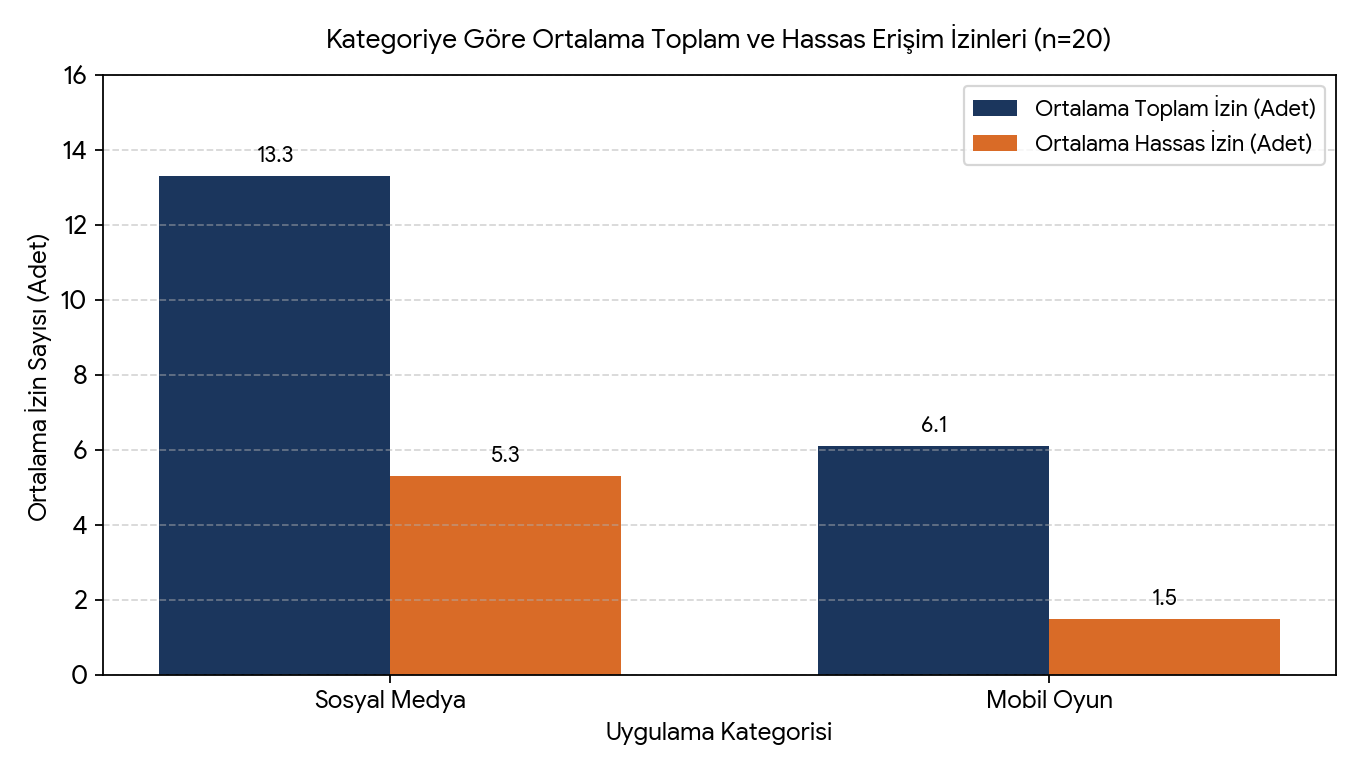

In [3]:
import matplotlib.pyplot as plt

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = range(len(ozet.index))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], ozet["toplam_izin_sayisi"], width=width, label="Ortalama Toplam İzin (Adet)", color="#1B365D")
bars2 = ax.bar([i + width/2 for i in x], ozet["hassas_izin_sayisi"], width=width, label="Ortalama Hassas İzin (Adet)", color="#D96B27")

ax.set_xticks(list(x))
ax.set_xticklabels(ozet.index, fontsize=11, fontweight="bold")
ax.set_xlabel("Uygulama Kategorisi")
ax.set_ylabel("Ortalama İzin Sayısı (Adet)")
ax.set_title("Kategoriye Göre Ortalama Toplam ve Hassas Erişim İzinleri (n=20)")
ax.set_ylim(0, 16)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend()

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.annotate(f"{h:.1f}", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=10, fontweight="bold")

fig.tight_layout()
fig.savefig(klasor / "grafik.png", dpi=160)
veri.to_csv(klasor / "kullanilan_veri.csv", index=False)
plt.show()

## E. Akademik yorum
**Veri kaynağı ve değişken:** Veri seti Google Play Store üzerinde en çok indirilen 10 Sosyal Medya ve 10 Mobil Oyun uygulamasının kamuya açık mağaza izin kayıtlarından derlenmiştir; bağımsız değişken `kategori` (Sosyal Medya / Mobil Oyun), bağımlı değişkenler ise `toplam_izin_sayisi` ve `hassas_izin_sayisi` (konum, mikrofon, kamera, rehber vb.) değişkenleridir.

**Toplam / ortalama ve birimler:** İncelenen 20 uygulamanın talep ettiği toplam izin sayısı **194 adet**, genel izin ortalaması ise uygulama başına **9.70 adet** olarak hesaplanmıştır. Kategori bazında incelendiğinde Sosyal Medya uygulamaları ortalama **13.30 adet** toplam izin (bunların **5.30 adedi** hassas izin) talep ederken, Mobil Oyunlar ortalama **6.10 adet** toplam izin (bunların **1.50 adedi** hassas izin) talep etmektedir.

**Grafikte görülen bulgu:** Sütun grafiğinde açıkça görüldüğü üzere, Sosyal Medya uygulamaları Mobil Oyunlara kıyasla hem toplam erişim izni sayısında 2 kattan fazla (13.3 vs 6.1 adet) hem de kişisel veri gizliliği açısından riskli kabul edilen hassas izin taleplerinde yaklaşık 3.5 kat daha yüksek (5.3 vs 1.5 adet) bir ortalamaya sahiptir.

**Sınırlılıklar ve ölçemediği şeyler:** Bu analiz yalnızca Google Play Store mağaza sayfalarında beyan edilen statik izin listelerini (20 Android uygulaması örnekleminde) kapsamaktadır; uygulamaların çalışma zamanında (runtime) bu izinleri ne sıklıkla tetiklediğini, arka planda üçüncü taraf reklam ağlarına (SDK) hangi verileri aktardığını veya iOS (App Store) ekosistemindeki izin davranışlarını ölçmemektedir.

**Ekipçe yapılan işlem:** Bireysel yürütülen bu projede (Yusuf Yurtman), 20 popüler uygulamanın mağaza izin verileri tek tek kontrol edilerek CSV formatına dönüştürülmüş, Python `pandas` kütüphanesiyle eksik veri ve grup ortalaması analizleri yapılmış ve `matplotlib` ile karşılaştırmalı sütun grafiği üretilmiştir.

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz.

## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı (`mobil_uygulama_izinleri.csv`)
- [x] Birim + veri kaynağı + lisans
- [x] En az 1 açıklamalı grafik (`sonuc/grafik.png`)
- [x] Toplam ve ortalama hesabı
- [x] 4–5 cümlelik yorum
- [x] README içinde ekip katkıları
- [x] GitHub repo bağlantısı (`https://github.com/yurtman421/mobil-uygulama-gizlilik-analizi`)
- [x] Gizli/kişisel veri ve anahtar bulunmuyor